# 05 Model Scientific Interest

Canonical modeling notebook for yearly scientific interest. This notebook builds the yearly SI dataset, ranks future high-interest pathogen-antibiotic pairs, and generates SI trend and shape plots.
Set `ANTIBIOTIC_ANALYSIS_LEVEL` to `"antibiotic"` for individual antibiotics, or to a column in `assets/antibiotic_coarsening_lookup.csv` such as `"Class"`.

## Inputs

- `yearly_amr_screened_pairs.parquet` from notebook 04c.
- Pathogen and antibiotic background-count parquets from notebook 04.
- SI analysis settings from `outputs/pipeline_config.yaml`.

## Outputs

- Yearly scientific-interest datasets and future-interest rankings under `outputs/parquets/`.
- SI trend, shape-screen tables, and plots under `outputs/`.
- Run notebook `05a_analyze_si_drivers.ipynb` after this notebook to build category driver summaries and plots.


In [14]:
%load_ext autoreload
%autoreload 2


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [15]:
from pathlib import Path
import sys

from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "amr").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "amr").exists():
    raise RuntimeError(f"Could not find repository root from {Path.cwd()}")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from amr.pipelines.si import (
    DEFAULT_DECREASING_SI_SUMMARY_COLUMNS,
    DEFAULT_SMOOTHED_SI_SHAPE_SUMMARY_COLUMNS,
    DEFAULT_INTERESTING_SUMMARY_COLUMNS,
    build_si_analysis_paths,
    build_yearly_si_dataset,
    filter_model_inputs_by_average_amr_publications,
    load_yearly_si_inputs,
    prepare_antibiotic_analysis_level,
    print_si_dataset_summary,
    rank_future_high_interest_pairs,
    save_interesting_si_plots,
    save_smoothed_si_screen_plots,
    select_existing_columns,
    summarize_smoothed_si_shapes,
    select_smoothed_si_shape_cases,
    select_decreasing_smoothed_si_trends,
    summarize_pair_publication_rates,
    summarize_pathogen_coverage,
)
from amr.pipeline_config import cfg, cfg_path, load_pipeline_config


## Configuration


In [16]:
PIPELINE_CONFIG = load_pipeline_config(project_root=PROJECT_ROOT)

OUTPUT_DIR = cfg_path(PIPELINE_CONFIG, "paths.output_dir", PROJECT_ROOT)
PARQUET_OUTPUT_DIR = cfg_path(PIPELINE_CONFIG, "paths.parquet_dir", PROJECT_ROOT)
PARQUET_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR = PARQUET_OUTPUT_DIR

YEARLY_SCREENED_PATH = cfg_path(PIPELINE_CONFIG, "paths.yearly_screened", PROJECT_ROOT)
PATHOGEN_BG_PATH = cfg_path(PIPELINE_CONFIG, "paths.pathogen_background", PROJECT_ROOT)
ANTIBIOTIC_BG_PATH = cfg_path(PIPELINE_CONFIG, "paths.antibiotic_background", PROJECT_ROOT)
ANTIBIOTIC_COARSENING_PATH = cfg_path(PIPELINE_CONFIG, "paths.antibiotic_coarsening", PROJECT_ROOT)

# Analysis level controls antibiotic grouping for all SI model inputs and outputs.
ANTIBIOTIC_ANALYSIS_LEVEL = cfg(PIPELINE_CONFIG, "si.antibiotic_analysis_level")
SI_PATHS = build_si_analysis_paths(PROJECT_ROOT, ANTIBIOTIC_ANALYSIS_LEVEL)
YEARLY_SI_PATH = SI_PATHS["yearly_si"]
RANK_OUTPUT_PATH = SI_PATHS["rank_output"]
INTERESTING_OUTPUT_PATH = SI_PATHS["interesting_output"]
INTERESTING_PLOT_DIR = SI_PATHS["interesting_plot_dir"]
DECREASING_SI_OUTPUT_PATH = PARQUET_OUTPUT_DIR / "decreasing_smoothed_si_trends.parquet"
CONVEX_SI_OUTPUT_PATH = PARQUET_OUTPUT_DIR / "convex_u_shaped_smoothed_si_trends.parquet"
CONCAVE_SI_OUTPUT_PATH = PARQUET_OUTPUT_DIR / "concave_inverted_u_smoothed_si_trends.parquet"
DECREASING_SI_PLOT_DIR = OUTPUT_DIR / "figures" / "decreasing_smoothed_si_plots"
CONVEX_SI_PLOT_DIR = OUTPUT_DIR / "figures" / "convex_u_shaped_smoothed_si_plots"
CONCAVE_SI_PLOT_DIR = OUTPUT_DIR / "figures" / "concave_inverted_u_smoothed_si_plots"

# Fit/rank window controls.
FIT_START_YEAR = cfg(PIPELINE_CONFIG, "si.fit_start_year")
FIT_END_YEAR = cfg(PIPELINE_CONFIG, "si.fit_end_year")
PUBLICATION_FILTER_END_YEAR = cfg(PIPELINE_CONFIG, "si.publication_filter_end_year")
CURVE_FIT_END_YEAR = cfg(PIPELINE_CONFIG, "si.curve_fit_end_year")
NUM_FUTURE_YEARS = cfg(PIPELINE_CONFIG, "si.num_future_years")
PLOT_END_YEAR = CURVE_FIT_END_YEAR + NUM_FUTURE_YEARS

# Pair filtering and interesting-pair ranking thresholds.
MIN_TOTAL_AMR_PUBLICATIONS = cfg(PIPELINE_CONFIG, "si.min_tot_amr_publications")
MIN_AMR_PAIR_PUBLICATION_COUNT = cfg(PIPELINE_CONFIG, "si.min_amr_pair_publication_count")
MIN_CURRENT_PREDICTED_COUNT = cfg(PIPELINE_CONFIG, "si.min_current_predicted_count")
MIN_CURRENT_AMR_COUNT = cfg(PIPELINE_CONFIG, "si.min_current_amr_count")
MIN_NUM_YEARS_WITH_VALID_COUNTS = cfg(PIPELINE_CONFIG, "si.min_num_years_with_valid_counts")
MIN_FUTURE_PREDICTED_COUNT = cfg(PIPELINE_CONFIG, "si.min_future_predicted_count")
MIN_SI_CHANGE = cfg(PIPELINE_CONFIG, "si.min_si_change")
MIN_POST_FIT_OBSERVED_YEARS = cfg(PIPELINE_CONFIG, "si.min_post_fit_observed_years")
MAX_POST_FIT_SI_ABS_PCT_ERROR_MEAN = cfg(PIPELINE_CONFIG, "si.max_post_fit_si_abs_pct_error_mean")
MAX_SI_LOESS_RESIDUAL_VARIANCE_MEAN = cfg(PIPELINE_CONFIG, "si.max_si_loess_residual_variance_mean")
FALLBACK_TOP_N = cfg(PIPELINE_CONFIG, "si.fallback_top_n")

MAX_INTERESTING_PLOTS = cfg(PIPELINE_CONFIG, "si.max_interesting_plots")
FIGURE_FORMAT = cfg(PIPELINE_CONFIG, "si.figure_format")
DISPLAY_PLOTS = cfg(PIPELINE_CONFIG, "si.display_plots")
MAX_DISPLAY_PLOTS = cfg(PIPELINE_CONFIG, "si.max_display_plots")
FILL_MISSING_AMR_COUNTS_WITH_ZERO = cfg(PIPELINE_CONFIG, "si.fill_missing_amr_counts_with_zero")
LOESS_FRAC = cfg(PIPELINE_CONFIG, "si.loess_frac")
LOESS_DEGREE = cfg(PIPELINE_CONFIG, "si.loess_degree")
TAIL_DAMPING_YEARS = cfg(PIPELINE_CONFIG, "si.tail_damping_years")
SHAPE_SCREEN_PLOT_COUNT = cfg(PIPELINE_CONFIG, "si.shape_screen_plot_count")


## Load Canonical Inputs


In [17]:
yearly_screened_df, pathogen_bg_df, antibiotic_bg_df, unified_decisions_df = load_yearly_si_inputs(
    yearly_screened_path=YEARLY_SCREENED_PATH,
    pathogen_background_path=PATHOGEN_BG_PATH,
    antibiotic_background_path=ANTIBIOTIC_BG_PATH,
)


yearly_screened rows: 28,897
yearly_screened unique pathogens: 335
yearly_screened unique antibiotics: 196
yearly_screened year range: 2000 - 2026
pathogen bg rows: 10,854
antibiotic bg rows: 5,346
unified decision rows available for driver analysis: 0


## Prepare Antibiotic Analysis Level

This step optionally aggregates from individual antibiotics to a selected coarsening column before SI modeling.


In [18]:
yearly_screened_model_df, antibiotic_bg_model_df, unified_decisions_model_df, analysis_summary = prepare_antibiotic_analysis_level(
    yearly_screened_df=yearly_screened_df,
    antibiotic_background_df=antibiotic_bg_df,
    unified_decisions_df=unified_decisions_df,
    coarsening_path=ANTIBIOTIC_COARSENING_PATH,
    analysis_level=ANTIBIOTIC_ANALYSIS_LEVEL,
)

yearly_screened_model_df.head(10)


Antibiotic analysis level: individual antibiotic.
model yearly rows: 28,897
model pathogen-antibiotic rows: 6,373
model antibiotic values: 196
model antibiotic background rows: 5,346
model unified decision rows: 0


,pathogen,antibiotic,year,count,pmids
0,Achromobacter denitrificans,Cefixime,2014,1,[24596716]
1,Achromobacter denitrificans,Ceftazidime,2014,1,[24596716]
2,Achromobacter denitrificans,Ceftriaxone,2014,1,[24596716]
3,Achromobacter denitrificans,Meropenem,2014,1,[24596716]
4,Achromobacter denitrificans,Meropenem,2026,1,[42008119]
5,Achromobacter mucicolens,Delafloxacin,2025,1,[40013782]
6,Achromobacter mucicolens,Eravacycline,2025,1,[40013782]
7,Achromobacter mucicolens,Meropenem,2025,1,[40013782]
8,Achromobacter mucicolens,Meropenem/vaborbactam,2025,1,[40013782]
9,Achromobacter mucicolens,Omadacycline,2025,1,[40013782]


## Build Yearly SI Dataset


## Filter Low-Volume Pairs

Keep only pathogen-antibiotic pairs with enough screened AMR publications on average across the fitting window. The average includes years with zero publications.


In [19]:
yearly_screened_model_unfiltered_df = yearly_screened_model_df.copy()

yearly_screened_model_df, unified_decisions_model_df, pair_publication_rates = filter_model_inputs_by_average_amr_publications(
    yearly_screened_model_df=yearly_screened_model_df,
    unified_decisions_model_df=unified_decisions_model_df,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    publication_filter_end_year=PUBLICATION_FILTER_END_YEAR,
    min_total_amr_publications=MIN_TOTAL_AMR_PUBLICATIONS,
)

pathogen_filter_summary_df = summarize_pathogen_coverage(
    source_df=yearly_screened_model_unfiltered_df,
    modeled_df=yearly_screened_model_df,
    source_label="model input before publication filter",
    modeled_label="model input after publication filter",
)

display(pathogen_filter_summary_df.query("status != 'present_in_both'"))
summarize_pair_publication_rates(pair_publication_rates, head=30)


AMR publication filter: kept 377 / 6,373 pairs with >= 50 total publications from 2000 to 2025.
model input before publication filter pathogens: 335
model input after publication filter pathogens: 33
Pathogens present in model input before publication filter but absent from model input after publication filter: 302
Achromobacter denitrificans, Achromobacter mucicolens, Achromobacter xylosoxidans, Acinetobacter calcoaceticus, Acinetobacter haemolyticus, Acinetobacter johnsonii, Acinetobacter junii, Acinetobacter lwoffii, Acinetobacter nosocomialis, Acinetobacter pittii, Acinetobacter radioresistens, Acinetobacter ursingii, Actinobacillus equuli, Actinotignum schaalii, Aerococcus viridans, Aeromonas caviae, Aeromonas dhakensis, Aeromonas hydrophila, Aeromonas jandaei, Aeromonas salmonicida, Aeromonas schubertii, Aeromonas sobria, Aeromonas veronii, Aggregatibacter actinomycetemcomitans, Agrobacterium radiobacter, Agrobacterium tumefaciens, Alcaligenes faecalis, Alistipes finegoldii, Arco

,pathogen,source_rows,source_publications,source_pairs,modeled_rows,modeled_publications,modeled_pairs,in_source,in_modeled,status
0,Achromobacter denitrificans,5,5,4,0.0,0.0,0.0,True,False,missing_from_modeled
1,Achromobacter mucicolens,9,9,9,0.0,0.0,0.0,True,False,missing_from_modeled
2,Achromobacter xylosoxidans,116,127,44,0.0,0.0,0.0,True,False,missing_from_modeled
3,Acinetobacter calcoaceticus,66,69,31,0.0,0.0,0.0,True,False,missing_from_modeled
4,Acinetobacter haemolyticus,2,2,2,0.0,0.0,0.0,True,False,missing_from_modeled
...,...,...,...,...,...,...,...,...,...,...
297,Weissella confusa,6,6,5,0.0,0.0,0.0,True,False,missing_from_modeled
298,Winkia neuii,7,7,7,0.0,0.0,0.0,True,False,missing_from_modeled
299,Yersinia enterocolitica,228,341,42,0.0,0.0,0.0,True,False,missing_from_modeled
300,Yersinia pestis,17,21,5,0.0,0.0,0.0,True,False,missing_from_modeled


,pathogen,antibiotic,fit_window_amr_publications,avg_amr_publications_per_year
4518,Staphylococcus aureus,Meticillin,4556,175.230769
1961,Escherichia coli,Ampicillin,2393,92.038462
2009,Escherichia coli,Ciprofloxacin,2005,77.115385
2105,Escherichia coli,Tetracycline,1875,72.115385
2111,Escherichia coli,Trimethoprim,1669,64.192308
2094,Escherichia coli,Sulfamethoxazole,1381,53.115385
4572,Staphylococcus aureus,Vancomycin,1369,52.653846
2095,Escherichia coli,Sulfamethoxazole/trimethoprim,1246,47.923077
2036,Escherichia coli,Gentamicin,1113,42.807692
1959,Escherichia coli,Amoxicillin,1090,41.923077


In the next code cell, the notebook combines the screened yearly AMR counts with background publication counts to calculate a scientific-interest score for each pathogen-antibiotic-year. In simple terms, it estimates how much attention each pair is getting beyond what would be expected from general research activity alone, then saves those results for ranking and forecasting in later steps.


In [20]:
si_df, pooled_model, design_columns = build_yearly_si_dataset(
    yearly_screened_model_df,
    pathogen_bg_df,
    antibiotic_bg_model_df,
    min_amr_pair_publication_count=MIN_AMR_PAIR_PUBLICATION_COUNT,
    output_path=YEARLY_SI_PATH,
)

print_si_dataset_summary(si_df)
si_pathogen_summary_df = summarize_pathogen_coverage(
    source_df=yearly_screened_model_df,
    modeled_df=si_df,
    source_label="filtered model input",
    modeled_label="yearly SI output",
)
display(si_pathogen_summary_df.query("status != 'present_in_both'"))
si_df.head(10)


SI rows: 8,835
SI pairs: 377
SI pathogens: 33
filtered model input pathogens: 33
yearly SI output pathogens: 33


,pathogen,source_rows,source_publications,source_pairs,modeled_rows,modeled_publications,modeled_pairs,in_source,in_modeled,status


,pathogen,antibiotic,year,count,pmids,bg_pathogen_n,bg_antibiotic_n,count_for_model,log_count,log_bg_pathogen_n,log_bg_antibiotic_n,expected_log_count_global,expected_count_global,SI,min_amr_pair_publication_count
0,Acinetobacter baumannii,Amikacin,2001,2,"[11192508, 12593705]",60,167,NaN,NaN,1.785330,2.225309,NaN,NaN,NaN,3.0
1,Acinetobacter baumannii,Amikacin,2002,2,"[11864948, 12481673]",80,156,NaN,NaN,1.908485,2.195900,NaN,NaN,NaN,3.0
2,Acinetobacter baumannii,Amikacin,2003,3,"[12872781, 14619453, 14748260]",80,183,3.0,0.602060,1.908485,2.264818,0.355068,1.264998,0.246992,3.0
3,Acinetobacter baumannii,Amikacin,2004,3,"[14964402, 15004037, 16163458]",93,180,3.0,0.602060,1.973128,2.257679,0.379639,1.396838,0.222421,3.0
4,Acinetobacter baumannii,Amikacin,2005,3,"[15667800, 16103700, 16258323]",139,187,3.0,0.602060,2.146128,2.274158,0.465417,1.920232,0.136643,3.0
5,Acinetobacter baumannii,Amikacin,2006,2,"[16597632, 16776825]",176,194,NaN,NaN,2.247973,2.290035,NaN,NaN,NaN,3.0
6,Acinetobacter baumannii,Amikacin,2008,3,"[18261233, 18792817, 18974485]",247,228,3.0,0.602060,2.394452,2.359835,0.623440,3.201842,-0.021380,3.0
7,Acinetobacter baumannii,Amikacin,2009,2,"[19795613, 20583564]",287,256,NaN,NaN,2.459392,2.409933,NaN,NaN,NaN,3.0
8,Acinetobacter baumannii,Amikacin,2010,8,"[20028819, 20107089, 20194701, 20499531, 20587...",342,265,8.0,0.954243,2.535294,2.424882,0.722322,4.276210,0.231920,3.0
9,Acinetobacter baumannii,Amikacin,2011,3,"[21803697, 22016680, 22122819]",421,266,3.0,0.602060,2.625312,2.426511,0.763048,4.794933,-0.160988,3.0


## Rank Reliable Future High-Interest Pairs


In [21]:
rank_df, interesting_df = rank_future_high_interest_pairs(
    si_df,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    min_current_predicted_count=MIN_CURRENT_PREDICTED_COUNT,
    min_current_amr_count=MIN_CURRENT_AMR_COUNT,
    min_num_years_with_valid_counts=MIN_NUM_YEARS_WITH_VALID_COUNTS,
    min_future_predicted_count=MIN_FUTURE_PREDICTED_COUNT,
    min_si_change=MIN_SI_CHANGE,
    min_post_fit_observed_years=MIN_POST_FIT_OBSERVED_YEARS,
    max_post_fit_si_abs_pct_error_mean=MAX_POST_FIT_SI_ABS_PCT_ERROR_MEAN,
    max_si_loess_residual_variance_mean=MAX_SI_LOESS_RESIDUAL_VARIANCE_MEAN,
    fallback_top_n=FALLBACK_TOP_N,
    min_amr_pair_publication_count=MIN_AMR_PAIR_PUBLICATION_COUNT,
    rank_output_path=RANK_OUTPUT_PATH,
    interesting_output_path=INTERESTING_OUTPUT_PATH,
    verbose=True,
)

select_existing_columns(
    interesting_df,
    DEFAULT_INTERESTING_SUMMARY_COLUMNS,
    head=30,
)

# All downstream SI visualizations, including shape screens, use the strict eligible-pair set.
eligible_pair_keys = interesting_df[["pathogen", "antibiotic"]].drop_duplicates()
eligible_rank_df = rank_df.merge(
    eligible_pair_keys,
    on=["pathogen", "antibiotic"],
    how="inner",
    validate="one_to_one",
)
print(f"Strictly eligible pairs for all SI plots and shape screens: {len(eligible_rank_df):,}")


[1/377] ranking Acinetobacter baumannii vs Amikacin
[2/377] ranking Acinetobacter baumannii vs Ampicillin
[3/377] ranking Acinetobacter baumannii vs Ampicillin/sulbactam
[4/377] ranking Acinetobacter baumannii vs Cefepime
[5/377] ranking Acinetobacter baumannii vs Cefiderocol
[6/377] ranking Acinetobacter baumannii vs Cefotaxime
[7/377] ranking Acinetobacter baumannii vs Ceftazidime
[8/377] ranking Acinetobacter baumannii vs Ceftriaxone
[9/377] ranking Acinetobacter baumannii vs Ciprofloxacin
[10/377] ranking Acinetobacter baumannii vs Colistin
[11/377] ranking Acinetobacter baumannii vs Gentamicin
[12/377] ranking Acinetobacter baumannii vs Levofloxacin
[13/377] ranking Acinetobacter baumannii vs Meropenem
[14/377] ranking Acinetobacter baumannii vs Minocycline
[15/377] ranking Acinetobacter baumannii vs Piperacillin
[16/377] ranking Acinetobacter baumannii vs Piperacillin/tazobactam
[17/377] ranking Acinetobacter baumannii vs Polymyxin-B
[18/377] ranking Acinetobacter baumannii vs Ri

## Plot Top Interesting Pairs


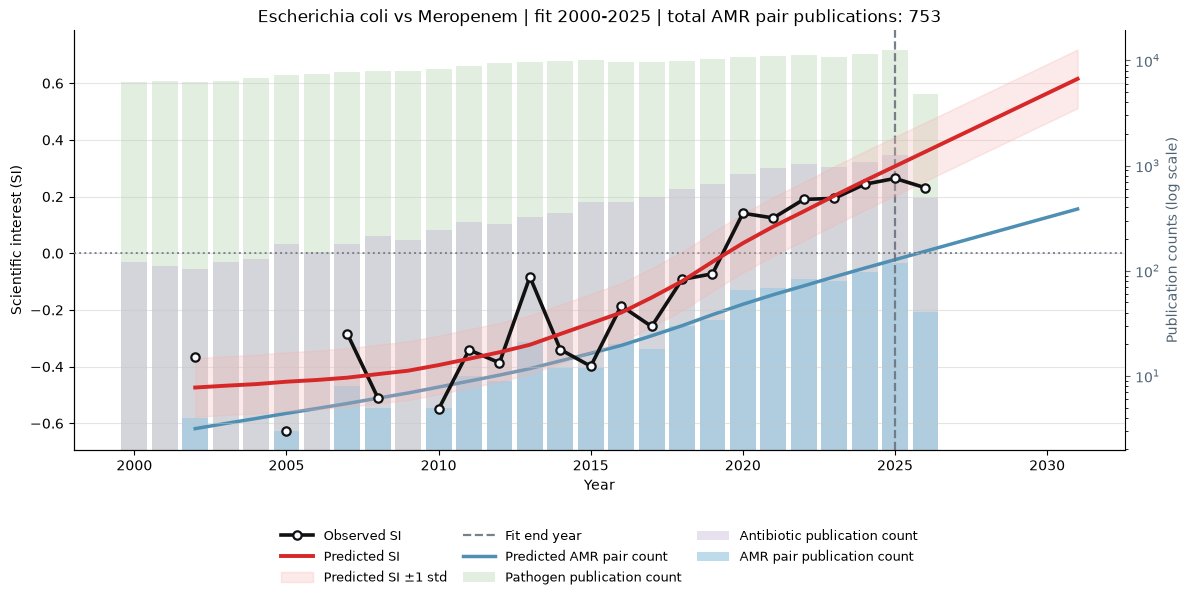

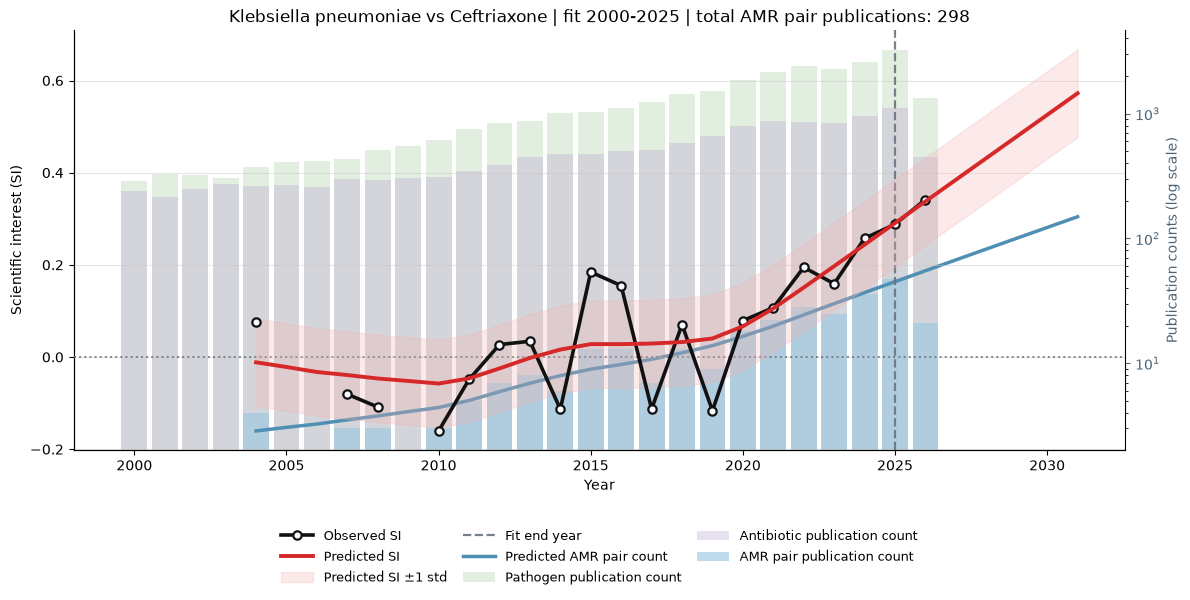

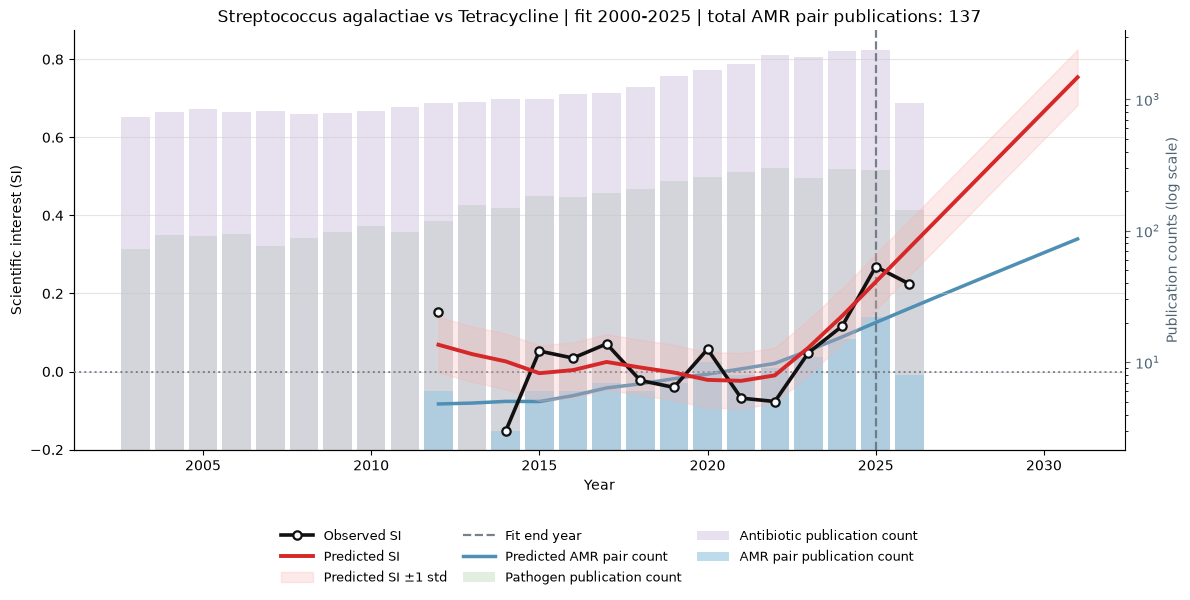

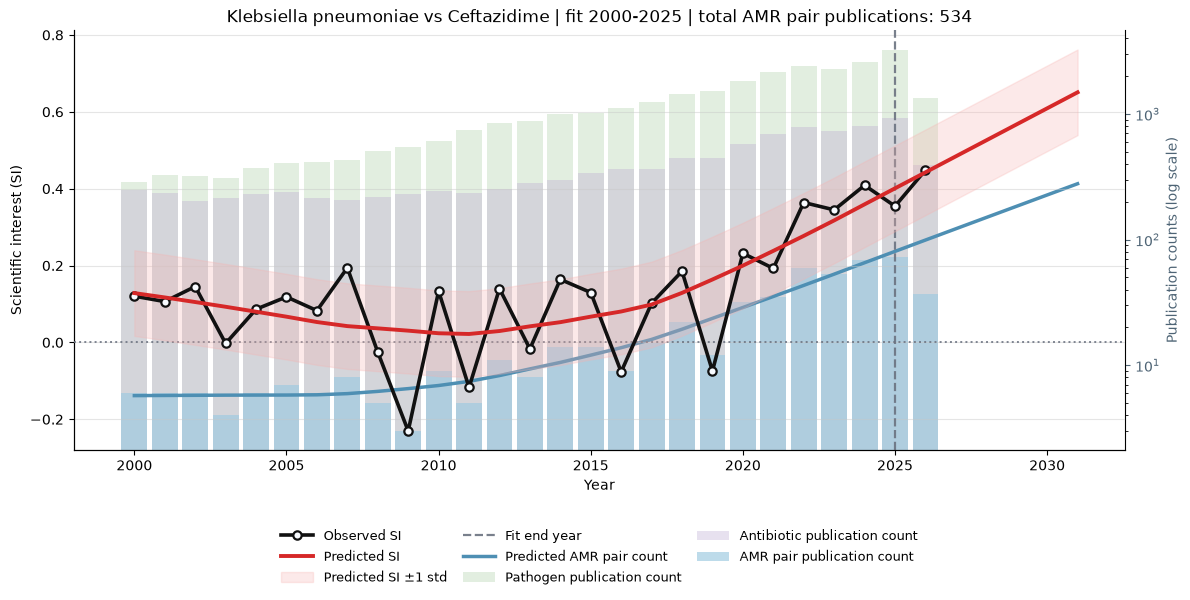

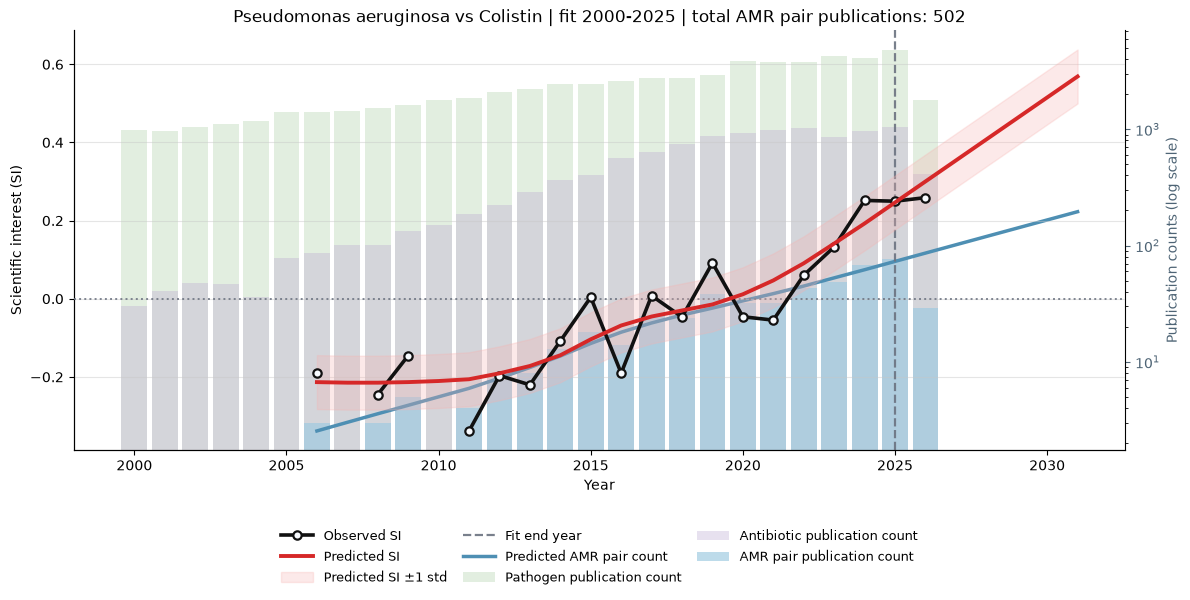

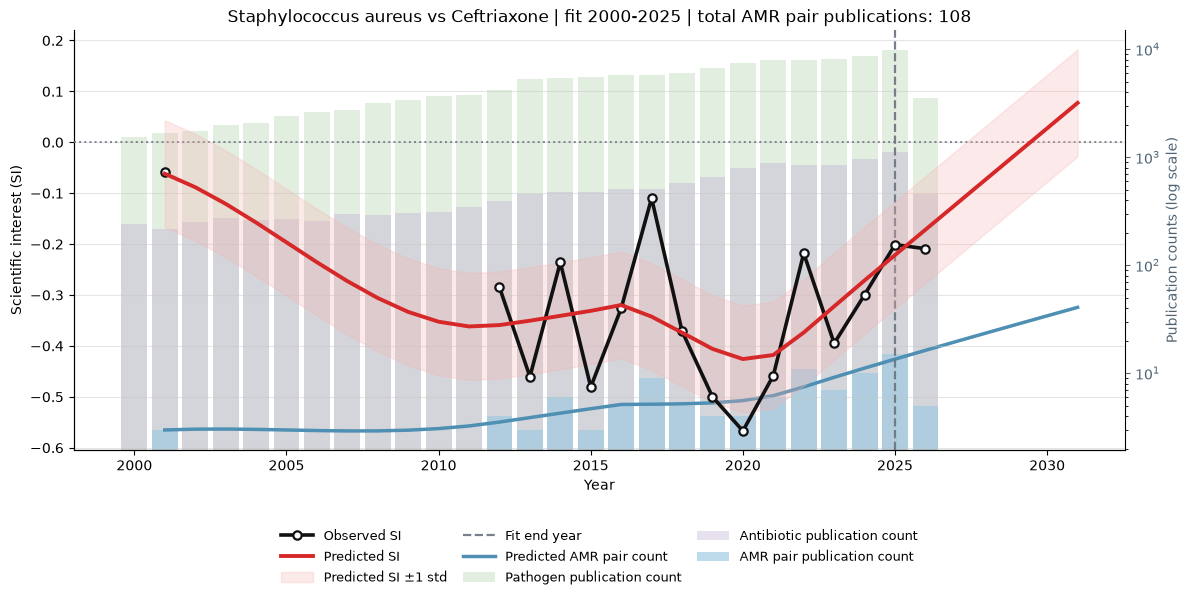

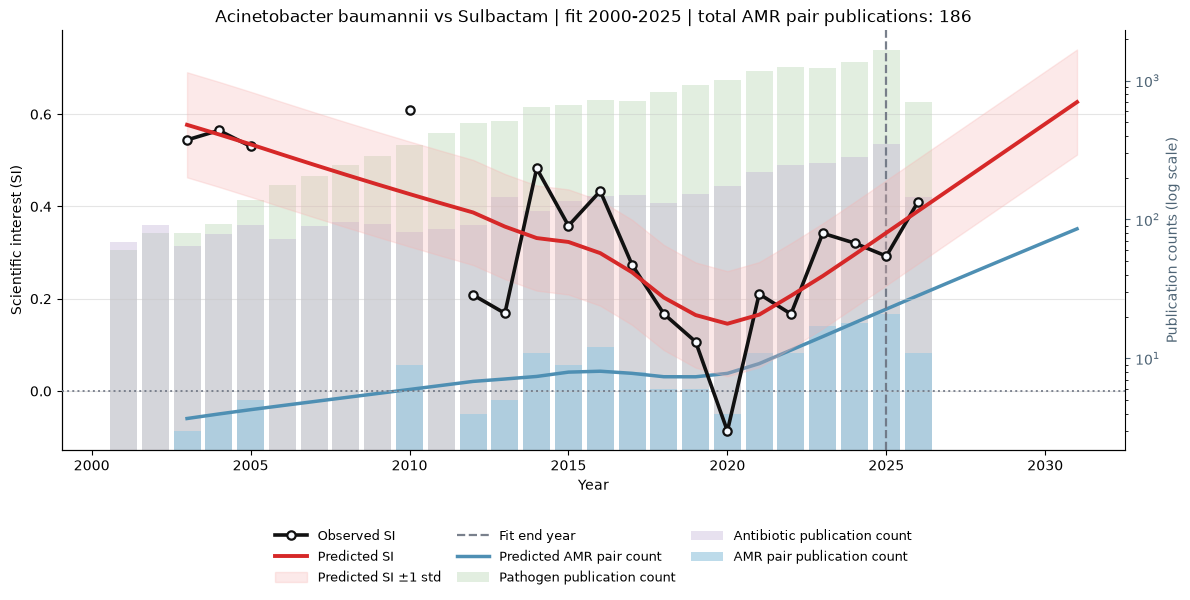

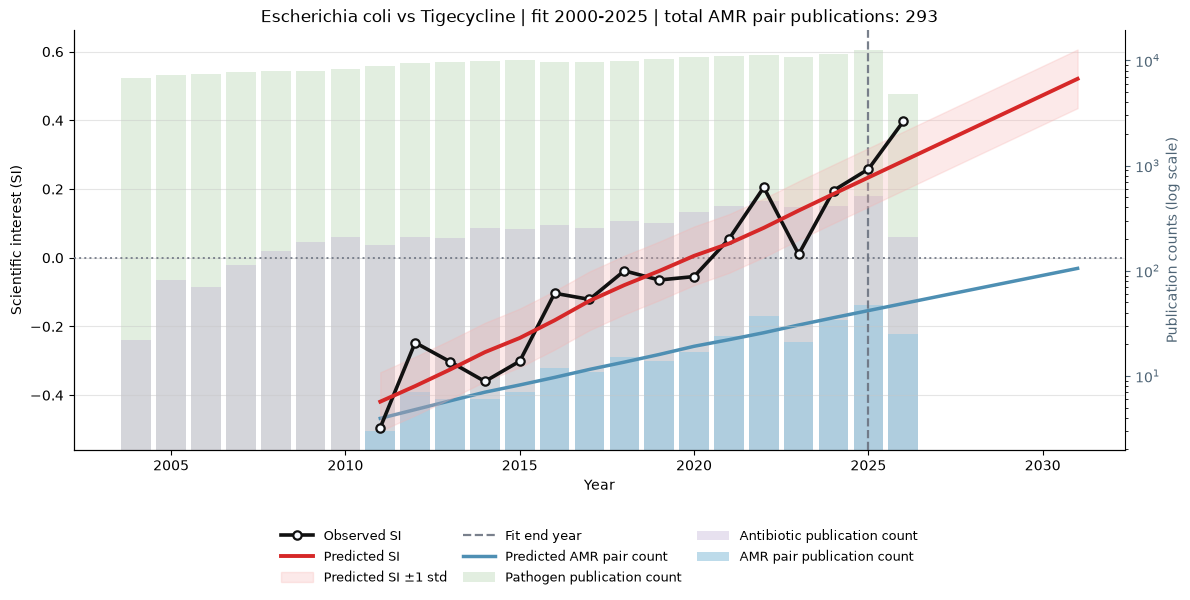

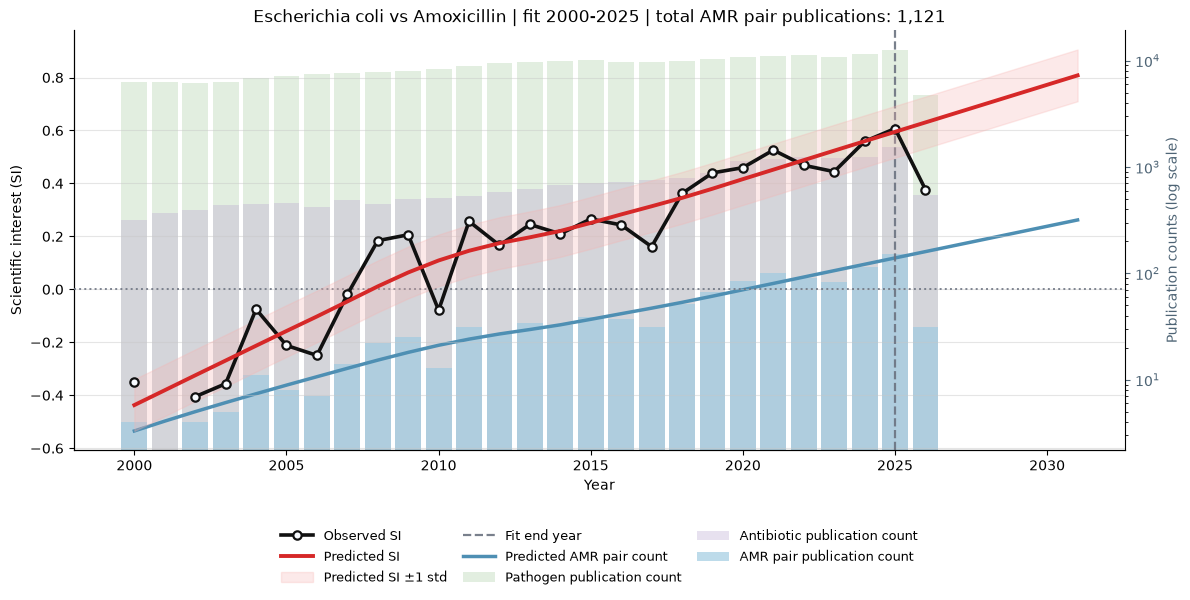

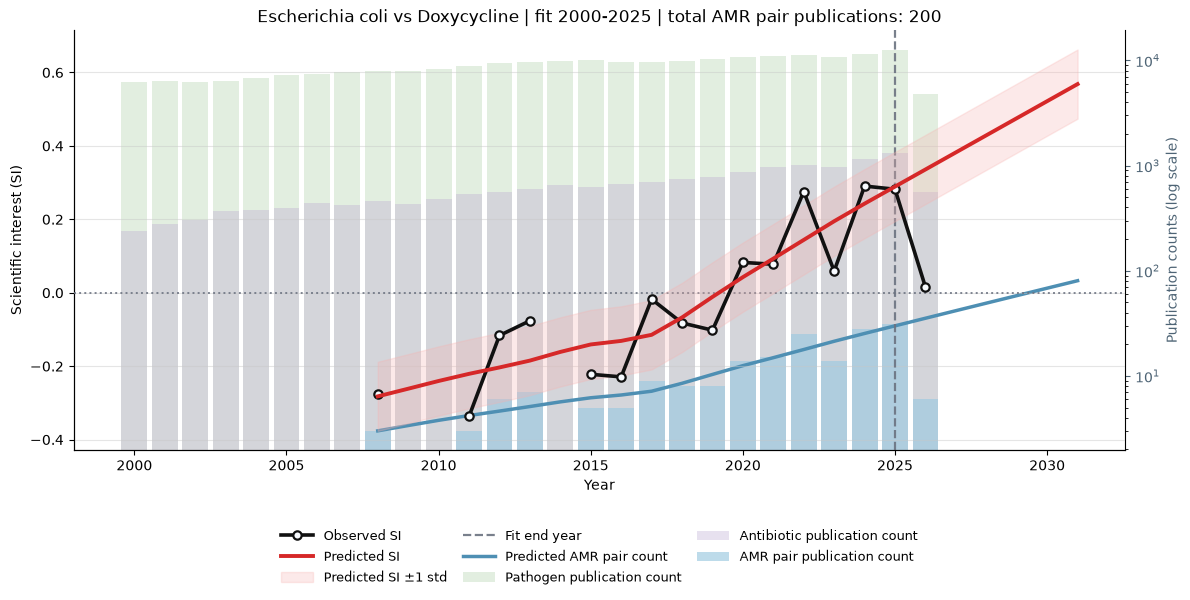

Saved 25 plots to /Users/f.costa/Code/Antimicrobial-Resistance/outputs/figures/interesting_yearly_si_plots
Displayed 10 plots inline.


In [22]:
saved_interesting_plots = save_interesting_si_plots(
    si_df=si_df,
    interesting_df=interesting_df,
    output_dir=INTERESTING_PLOT_DIR,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    pathogen_background_df=pathogen_bg_df,
    antibiotic_background_df=antibiotic_bg_model_df,
    max_plots=MAX_INTERESTING_PLOTS,
    loess_frac=0.6,
    loess_degree=1,
    tail_damping_years=None,
    min_amr_pair_publication_count=MIN_AMR_PAIR_PUBLICATION_COUNT,
    min_num_years_with_valid_counts=MIN_NUM_YEARS_WITH_VALID_COUNTS,
    fill_missing_amr_counts_with_zero=FILL_MISSING_AMR_COUNTS_WITH_ZERO,
    figure_format=FIGURE_FORMAT,
    display_plots=DISPLAY_PLOTS,
    max_display_plots=MAX_DISPLAY_PLOTS,
)


## Additional SI Shape Screens


### Largest Decreasing Smoothed SI Trends


In [23]:
decreasing_smoothed_si_df = select_decreasing_smoothed_si_trends(
    eligible_rank_df,
    output_path=DECREASING_SI_OUTPUT_PATH,
)

select_existing_columns(
    decreasing_smoothed_si_df,
    DEFAULT_DECREASING_SI_SUMMARY_COLUMNS,
    head=10,
)


Saved decreasing smoothed SI table: 0 rows -> /Users/f.costa/Code/Antimicrobial-Resistance/outputs/parquets/decreasing_smoothed_si_trends.parquet


,pathogen,antibiotic,reference_year,future_year,current_predicted_SI,future_predicted_SI,si_change,current_predicted_count,future_predicted_count,si_loess_residual_variance_mean,post_fit_si_abs_pct_error_mean


### Most Convex and Concave Smoothed SI Curves


In [24]:
smoothed_si_shape_df = summarize_smoothed_si_shapes(
    eligible_rank_df,
    si_df,
    fit_start_year=FIT_START_YEAR,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    loess_frac=0.6,
    loess_degree=1,
    tail_damping_years=None,
    min_amr_pair_publication_count=MIN_AMR_PAIR_PUBLICATION_COUNT,
    min_num_years_with_valid_counts=MIN_NUM_YEARS_WITH_VALID_COUNTS,
)

most_convex_smoothed_si_df, most_concave_smoothed_si_df = select_smoothed_si_shape_cases(
    smoothed_si_shape_df,
    top_n=10,
    convex_output_path=CONVEX_SI_OUTPUT_PATH,
    concave_output_path=CONCAVE_SI_OUTPUT_PATH,
)

print("Most convex U-shaped smoothed SI curves")
select_existing_columns(
    most_convex_smoothed_si_df,
    DEFAULT_SMOOTHED_SI_SHAPE_SUMMARY_COLUMNS,
    head=10,
)

print("Most concave inverted-U smoothed SI curves")
select_existing_columns(
    most_concave_smoothed_si_df,
    DEFAULT_SMOOTHED_SI_SHAPE_SUMMARY_COLUMNS,
    head=10,
)


Saved convex U-shaped smoothed SI table: 10 rows -> /Users/f.costa/Code/Antimicrobial-Resistance/outputs/parquets/convex_u_shaped_smoothed_si_trends.parquet
Saved concave inverted-U smoothed SI table: 0 rows -> /Users/f.costa/Code/Antimicrobial-Resistance/outputs/parquets/concave_inverted_u_smoothed_si_trends.parquet
Most convex U-shaped smoothed SI curves
Most concave inverted-U smoothed SI curves


,pathogen,antibiotic,shape_start_year,shape_midpoint_year,curve_fit_end_year,shape_end_year,start_predicted_SI,midpoint_predicted_SI,end_predicted_SI,endpoint_balance_abs_diff,convex_u_score,concave_cap_score,si_quadratic_coef,si_quadratic_r2,si_change,si_loess_residual_variance_mean


### Plots for Additional SI Shape Screens

The following plot groups are separate shape categories. All three groups are restricted to the strictly eligible SI pairs identified above:

1. Decreasing SI
2. Convex U-shaped SI
3. Concave inverted-U-shaped SI


In [25]:
# SHAPE_SCREEN_PLOT_COUNT is loaded from PIPELINE_CONFIG in the main config cell.


Category: Decreasing SI
Saved 0 smoothed SI screen plots to /Users/f.costa/Code/Antimicrobial-Resistance/outputs/figures/decreasing_smoothed_si_plots
Category: Convex U-shaped SI


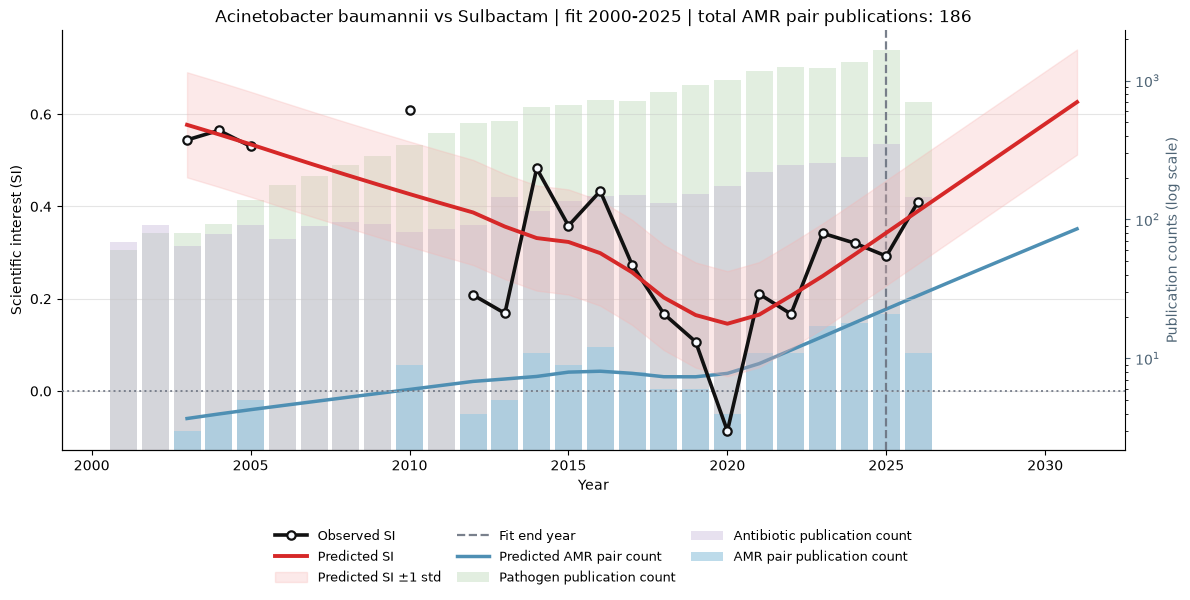

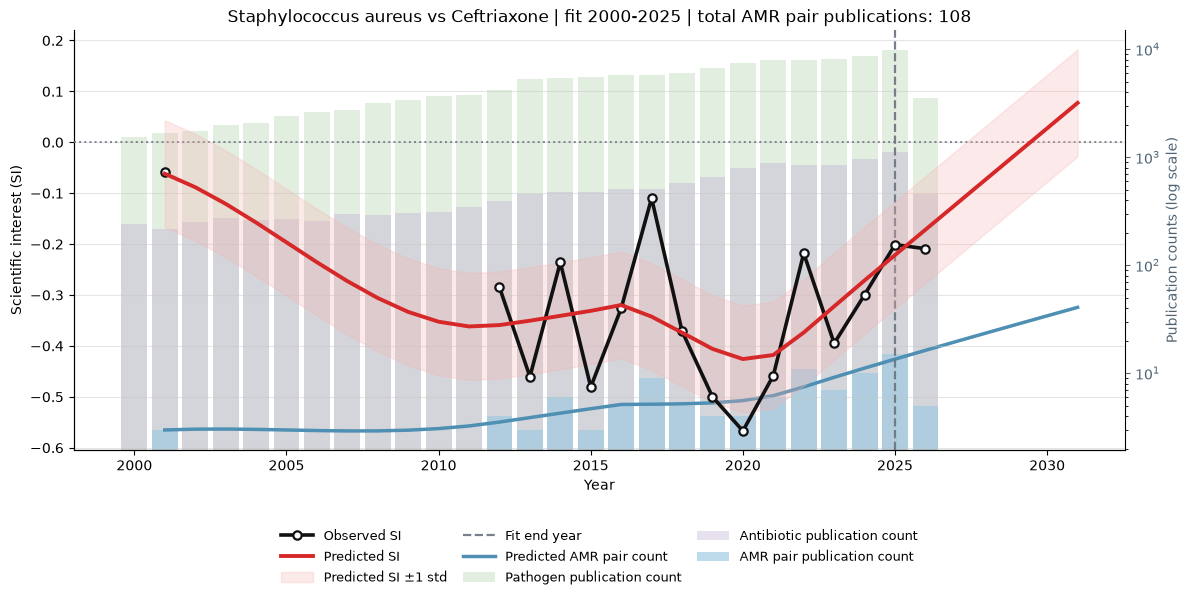

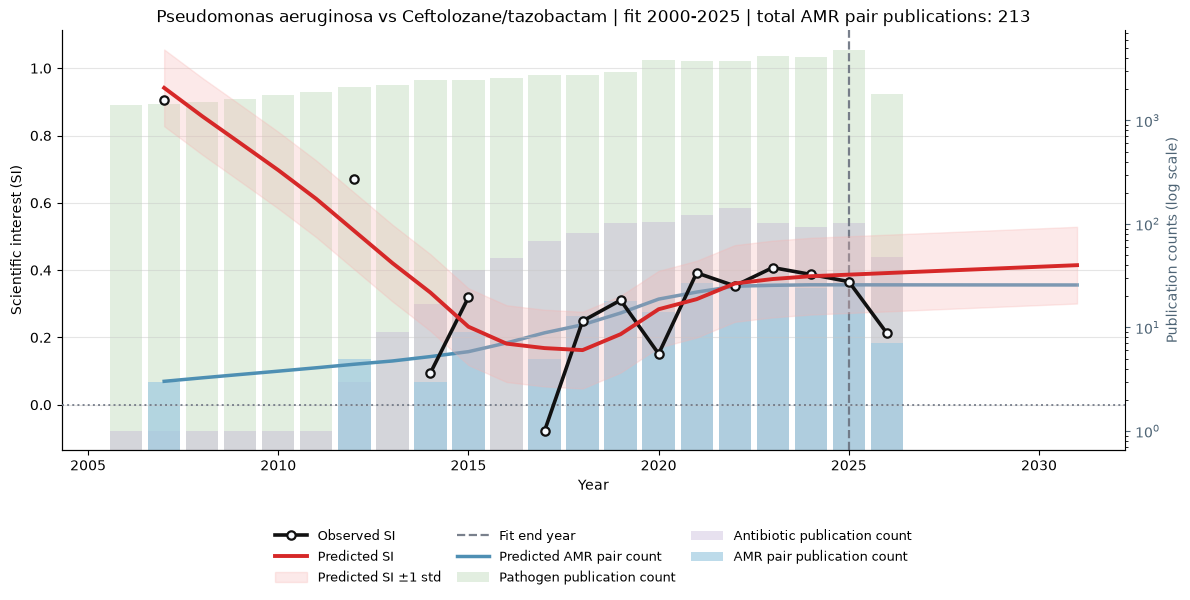

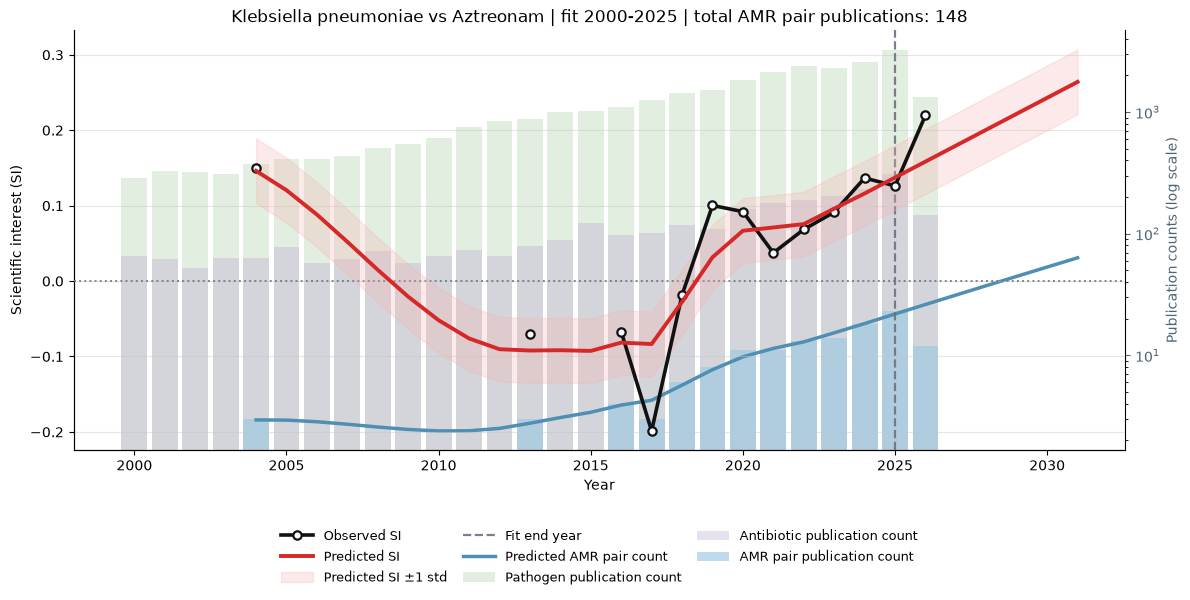

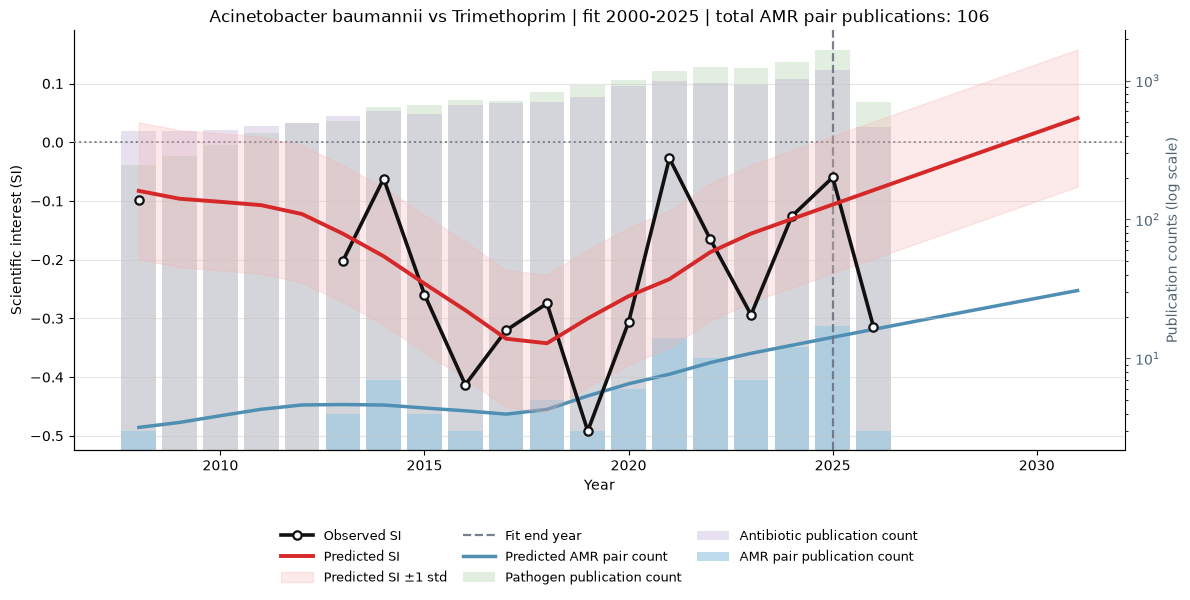

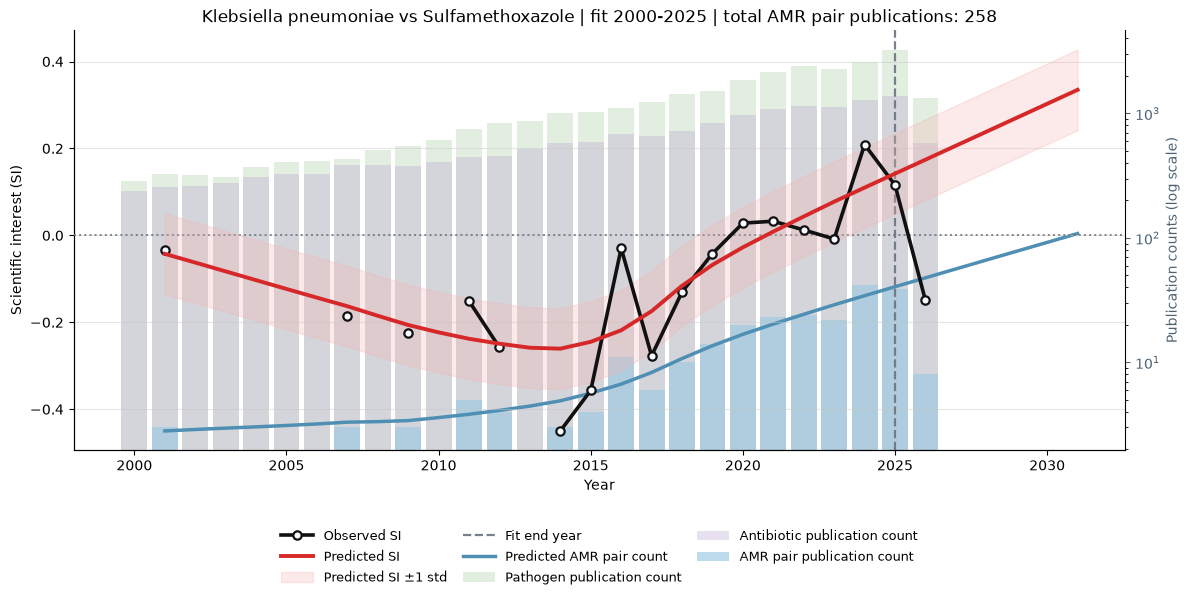

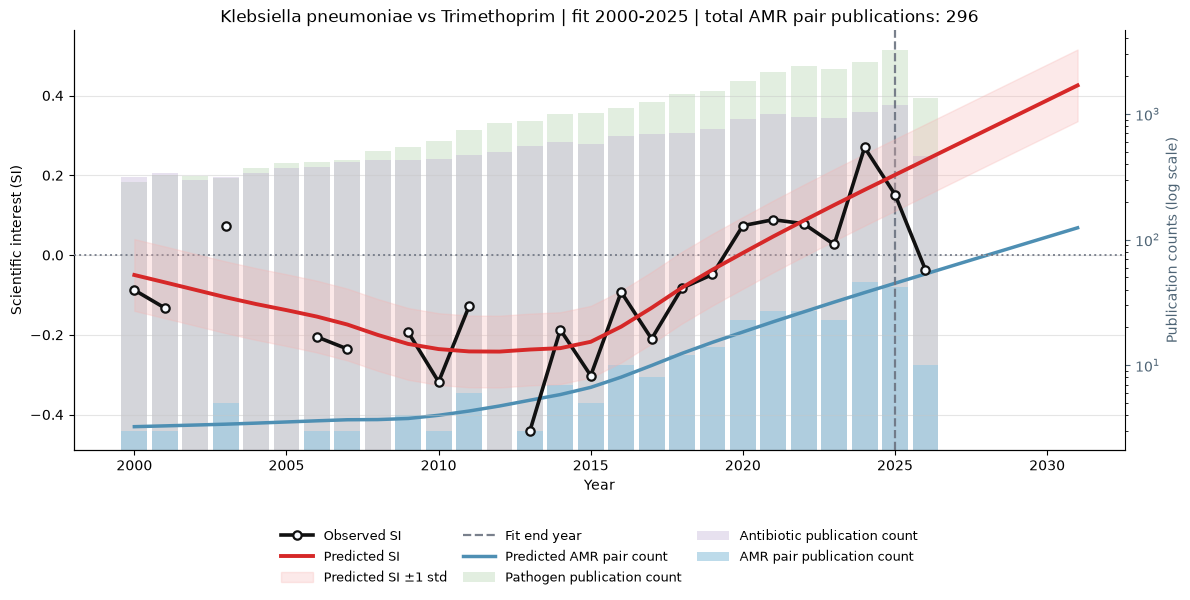

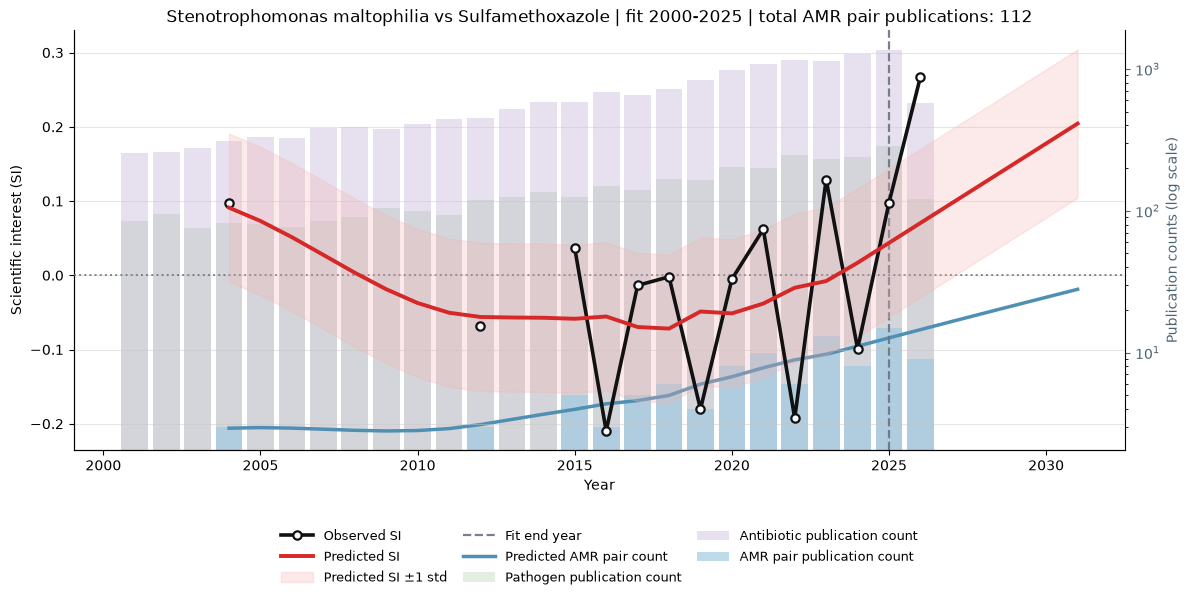

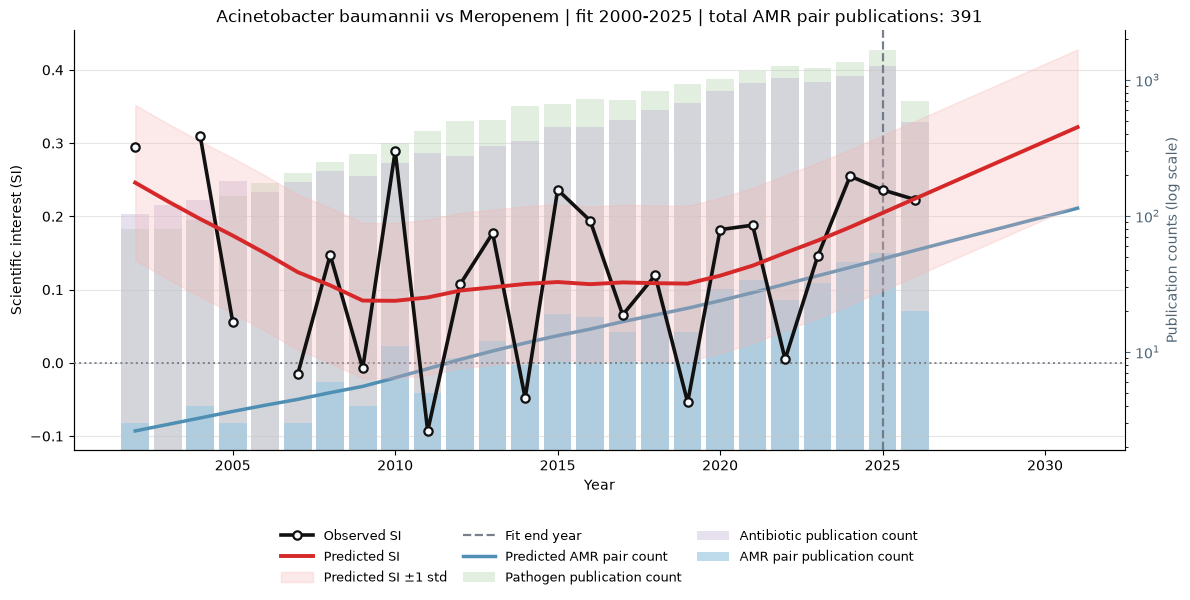

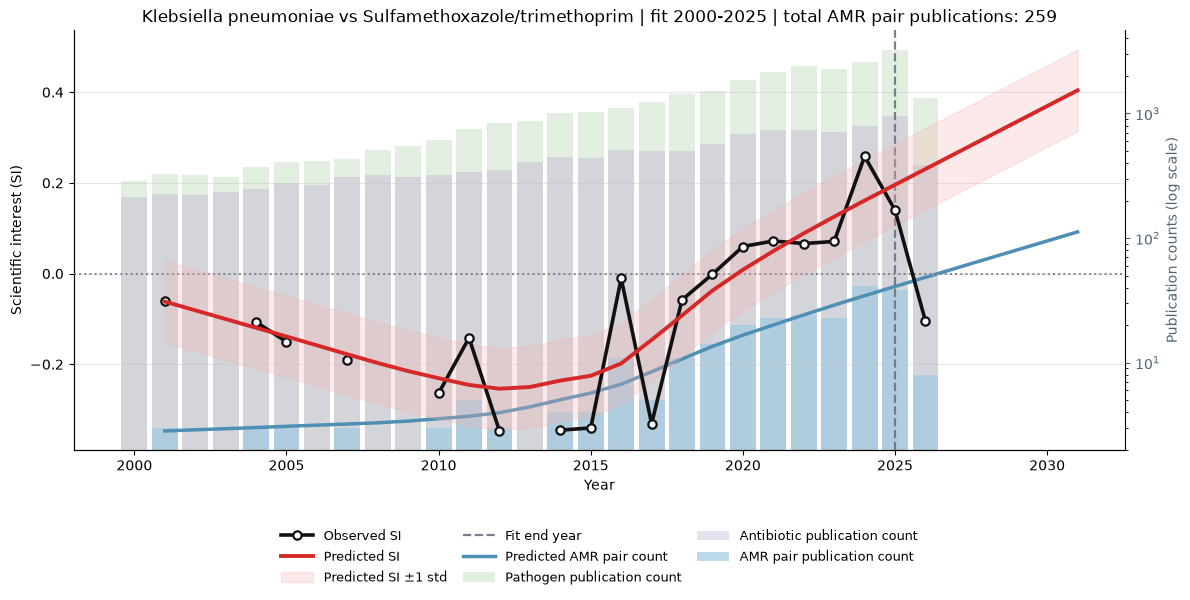

Saved 10 smoothed SI screen plots to /Users/f.costa/Code/Antimicrobial-Resistance/outputs/figures/convex_u_shaped_smoothed_si_plots
Category: Concave inverted-U-shaped SI
Saved 0 smoothed SI screen plots to /Users/f.costa/Code/Antimicrobial-Resistance/outputs/figures/concave_inverted_u_smoothed_si_plots


0

In [27]:
print('='*100)
print("Category: Decreasing SI")
save_smoothed_si_screen_plots(
    screen_df=decreasing_smoothed_si_df,
    si_df=si_df,
    output_dir=DECREASING_SI_PLOT_DIR,
    fit_start_year=FIT_START_YEAR,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    pathogen_background_df=pathogen_bg_df,
    antibiotic_background_df=antibiotic_bg_model_df,
    max_plots=SHAPE_SCREEN_PLOT_COUNT,
    min_amr_pair_publication_count=MIN_AMR_PAIR_PUBLICATION_COUNT,
    min_num_years_with_valid_counts=MIN_NUM_YEARS_WITH_VALID_COUNTS,
    figure_format=FIGURE_FORMAT,
    display_plots=DISPLAY_PLOTS,
)

print('='*100)
print("Category: Convex U-shaped SI")
save_smoothed_si_screen_plots(
    screen_df=most_convex_smoothed_si_df,
    si_df=si_df,
    output_dir=CONVEX_SI_PLOT_DIR,
    fit_start_year=FIT_START_YEAR,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    pathogen_background_df=pathogen_bg_df,
    antibiotic_background_df=antibiotic_bg_model_df,
    max_plots=SHAPE_SCREEN_PLOT_COUNT,
    min_amr_pair_publication_count=MIN_AMR_PAIR_PUBLICATION_COUNT,
    min_num_years_with_valid_counts=MIN_NUM_YEARS_WITH_VALID_COUNTS,
    figure_format=FIGURE_FORMAT,
    display_plots=DISPLAY_PLOTS,
)

print('='*100)
print("Category: Concave inverted-U-shaped SI")
save_smoothed_si_screen_plots(
    screen_df=most_concave_smoothed_si_df,
    si_df=si_df,
    output_dir=CONCAVE_SI_PLOT_DIR,
    fit_start_year=FIT_START_YEAR,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    pathogen_background_df=pathogen_bg_df,
    antibiotic_background_df=antibiotic_bg_model_df,
    max_plots=SHAPE_SCREEN_PLOT_COUNT,
    min_amr_pair_publication_count=MIN_AMR_PAIR_PUBLICATION_COUNT,
    min_num_years_with_valid_counts=MIN_NUM_YEARS_WITH_VALID_COUNTS,
    figure_format=FIGURE_FORMAT,
    display_plots=DISPLAY_PLOTS,
)
